# 10 - Deep Learning Pathogenicity Benchmark (Tabular ResNet)
**Project**: AI-Based Structural Variant Prioritization from Long-Read Sequencing Using Explainable Machine Learning  
**Author**: Data Science & Genomics Team  
**Date**: August 2026

## Objective
Address the accuracy and calibration limitations of standard tree models on imbalanced genomic structural variants using a **Deep Residual Tabular Neural Network (Tabular ResNet)** in PyTorch.

1. **Architecture**: Multilayer Residual Network with Skip Connections, Layer/Batch Normalization, SiLU activations, and Dropout regularization.
2. **Training**: AdamW optimizer, Cosine Annealing learning rate schedule, and Early Stopping on holdout validation loss.
3. **Threshold Optimization**: Systematic validation of decision threshold $\tau$ to maximize balanced accuracy and overall diagnostic accuracy.
4. **Comprehensive Evaluation**:
   - Side-by-side Confusion Matrices (Default $\tau = 0.5$ vs. Optimal $\tau$).
   - Precision-Recall (PR) and ROC Curves benchmarked against XGBoost, LightGBM, and Random Forest.
   - Calibration Curve & Reliability Diagram.
   - Threshold vs. Metric curves (Accuracy, Balanced Accuracy, F1-Score).


In [1]:
import os
import sys

# Ensure repository root is in sys.path
for candidate in [os.path.abspath("."), os.path.abspath("..")]:
    if os.path.isdir(os.path.join(candidate, "src")) and candidate not in sys.path:
        sys.path.insert(0, candidate)

def resolve_path(p):
    for candidate in [p, os.path.join("..", p), os.path.join("data", p), os.path.join("..", "data", p)]:
        if os.path.exists(candidate):
            return candidate
    return p

import json
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, roc_auc_score, f1_score,
    confusion_matrix, precision_recall_curve, roc_curve, auc, brier_score_loss,
    classification_report
)
from sklearn.calibration import calibration_curve

# Styling
sns.set_theme(style="whitegrid")
plt.rcParams['font.size'] = 11

# Set reproducible seeds
torch.manual_seed(42)
np.random.seed(42)

# Load data partitions
train_path = resolve_path("processed/train.csv.gz")
val_path = resolve_path("processed/val.csv.gz")
test_path = resolve_path("processed/test.csv.gz")

df_train = pd.read_csv(train_path)
df_val = pd.read_csv(val_path)
df_test = pd.read_csv(test_path)

with open(resolve_path("models/feature_names.json"), "r") as f:
    feature_cols = json.load(f)

X_train_raw = df_train[feature_cols].values.astype(np.float32)
y_train = df_train["target"].values.astype(np.float32)

X_val_raw = df_val[feature_cols].values.astype(np.float32)
y_val = df_val["target"].values.astype(np.float32)

X_test_raw = df_test[feature_cols].values.astype(np.float32)
y_test = df_test["target"].values.astype(np.float32)

print("Dataset Partitions (Chromosomal Disjoint):")
print(f"  Train Set (Chr 1-14):      {X_train_raw.shape[0]:,} samples | Positive Rate: {y_train.mean():.1%}")
print(f"  Val Set   (Chr 15-18):     {X_val_raw.shape[0]:,} samples  | Positive Rate: {y_val.mean():.1%}")
print(f"  Test Set  (Chr 19-22,X,Y): {X_test_raw.shape[0]:,} samples  | Positive Rate: {y_test.mean():.1%}")
print(f"  Input Features:            {len(feature_cols)} intrinsic genomic/popgen features")


Dataset Partitions (Chromosomal Disjoint):
  Train Set (Chr 1-14):      25,158 samples | Positive Rate: 78.5%
  Val Set   (Chr 15-18):     8,546 samples  | Positive Rate: 86.6%
  Test Set  (Chr 19-22,X,Y): 8,854 samples  | Positive Rate: 82.8%
  Input Features:            24 intrinsic genomic/popgen features


In [2]:
# Standardize features (fit on train, transform val and test)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_raw)
X_val_scaled = scaler.transform(X_val_raw)
X_test_scaled = scaler.transform(X_test_raw)

# Save scaler
models_dir = resolve_path("models")
os.makedirs(models_dir, exist_ok=True)
joblib.dump(scaler, os.path.join(models_dir, "dl_scaler.joblib"))

# Prepare PyTorch DataLoaders
BATCH_SIZE = 256
train_dataset = TensorDataset(torch.from_numpy(X_train_scaled), torch.from_numpy(y_train))
val_dataset = TensorDataset(torch.from_numpy(X_val_scaled), torch.from_numpy(y_val))
test_dataset = TensorDataset(torch.from_numpy(X_test_scaled), torch.from_numpy(y_test))

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=512, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=512, shuffle=False)

print(f"Prepared DataLoaders with Batch Size {BATCH_SIZE} ({len(train_loader)} batches/epoch).")


Prepared DataLoaders with Batch Size 256 (99 batches/epoch).


In [3]:
class ResBlock(nn.Module):
    """
    Residual Block for Tabular Data:
    x -> Linear -> BatchNorm -> SiLU -> Dropout -> Linear -> BatchNorm -> + x -> SiLU
    """
    def __init__(self, dim, dropout=0.2):
        super().__init__()
        self.block = nn.Sequential(
            nn.Linear(dim, dim),
            nn.BatchNorm1d(dim),
            nn.SiLU(),
            nn.Dropout(dropout),
            nn.Linear(dim, dim),
            nn.BatchNorm1d(dim),
        )
        self.act = nn.SiLU()
        
    def forward(self, x):
        return self.act(x + self.block(x))


class TabularResNet(nn.Module):
    """
    Deep Residual Network tailored for Continuous Genomic Tabular Features.
    """
    def __init__(self, in_features, hidden_dim=128, num_blocks=3, dropout=0.2):
        super().__init__()
        self.stem = nn.Sequential(
            nn.Linear(in_features, hidden_dim),
            nn.BatchNorm1d(hidden_dim),
            nn.SiLU()
        )
        self.blocks = nn.ModuleList([ResBlock(hidden_dim, dropout) for _ in range(num_blocks)])
        self.head = nn.Sequential(
            nn.Linear(hidden_dim, 64),
            nn.BatchNorm1d(64),
            nn.SiLU(),
            nn.Dropout(dropout / 2),
            nn.Linear(64, 1)
        )
        
    def forward(self, x):
        h = self.stem(x)
        for block in self.blocks:
            h = block(h)
        return self.head(h).squeeze(-1)

model = TabularResNet(in_features=len(feature_cols), hidden_dim=128, num_blocks=3, dropout=0.2)
print("Tabular ResNet Architecture:")
print(model)
print(f"Total Trainable Parameters: {sum(p.numel() for p in model.parameters() if p.requires_grad):,}")


Tabular ResNet Architecture:
TabularResNet(
  (stem): Sequential(
    (0): Linear(in_features=24, out_features=128, bias=True)
    (1): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): SiLU()
  )
  (blocks): ModuleList(
    (0-2): 3 x ResBlock(
      (block): Sequential(
        (0): Linear(in_features=128, out_features=128, bias=True)
        (1): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (2): SiLU()
        (3): Dropout(p=0.2, inplace=False)
        (4): Linear(in_features=128, out_features=128, bias=True)
        (5): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      )
      (act): SiLU()
    )
  )
  (head): Sequential(
    (0): Linear(in_features=128, out_features=64, bias=True)
    (1): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): SiLU()
    (3): Dropout(p=0.1, inplace=False)
    (4): Linear(in_features=64, out_fea

In [4]:
EPOCHS = 25
criterion = nn.BCEWithLogitsLoss()
optimizer = optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)

history = {
    "train_loss": [],
    "val_loss": [],
    "val_roc_auc": [],
    "val_pr_auc": []
}

best_val_roc = 0.0
best_state = None

print("Training Tabular ResNet...")
for epoch in range(1, EPOCHS + 1):
    model.train()
    running_loss = 0.0
    for bx, by in train_loader:
        optimizer.zero_grad()
        logits = model(bx)
        loss = criterion(logits, by)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * len(by)
        
    scheduler.step()
    epoch_train_loss = running_loss / len(train_dataset)
    
    # Validation evaluation
    model.eval()
    val_loss = 0.0
    val_probs = []
    with torch.no_grad():
        for bx, by in val_loader:
            logits = model(bx)
            loss = criterion(logits, by)
            val_loss += loss.item() * len(by)
            val_probs.extend(torch.sigmoid(logits).numpy())
            
    epoch_val_loss = val_loss / len(val_dataset)
    val_probs = np.array(val_probs)
    
    val_roc = roc_auc_score(y_val, val_probs)
    val_p, val_r, _ = precision_recall_curve(y_val, val_probs)
    val_pr = auc(val_r, val_p)
    
    history["train_loss"].append(epoch_train_loss)
    history["val_loss"].append(epoch_val_loss)
    history["val_roc_auc"].append(val_roc)
    history["val_pr_auc"].append(val_pr)
    
    if val_roc > best_val_roc:
        best_val_roc = val_roc
        best_state = model.state_dict().copy()
        
    if epoch % 5 == 0 or epoch == EPOCHS:
        print(f"Epoch [{epoch:02d}/{EPOCHS:02d}] - Train Loss: {epoch_train_loss:.4f} | Val Loss: {epoch_val_loss:.4f} | Val ROC-AUC: {val_roc:.4f} | Val PR-AUC: {val_pr:.4f}")

# Restore best weights
model.load_state_dict(best_state)
torch.save(best_state, os.path.join(models_dir, "tabular_resnet.pth"))
print(f"\nBest Validation ROC-AUC: {best_val_roc:.4f}. Model serialized to models/tabular_resnet.pth.")


Training Tabular ResNet...


Epoch [05/25] - Train Loss: 0.2846 | Val Loss: 0.3147 | Val ROC-AUC: 0.8608 | Val PR-AUC: 0.9714


Epoch [10/25] - Train Loss: 0.2770 | Val Loss: 0.3294 | Val ROC-AUC: 0.8663 | Val PR-AUC: 0.9723


Epoch [15/25] - Train Loss: 0.2730 | Val Loss: 0.2942 | Val ROC-AUC: 0.8733 | Val PR-AUC: 0.9730


Epoch [20/25] - Train Loss: 0.2698 | Val Loss: 0.2779 | Val ROC-AUC: 0.8846 | Val PR-AUC: 0.9758


Epoch [25/25] - Train Loss: 0.2684 | Val Loss: 0.2891 | Val ROC-AUC: 0.8820 | Val PR-AUC: 0.9753

Best Validation ROC-AUC: 0.8867. Model serialized to models/tabular_resnet.pth.


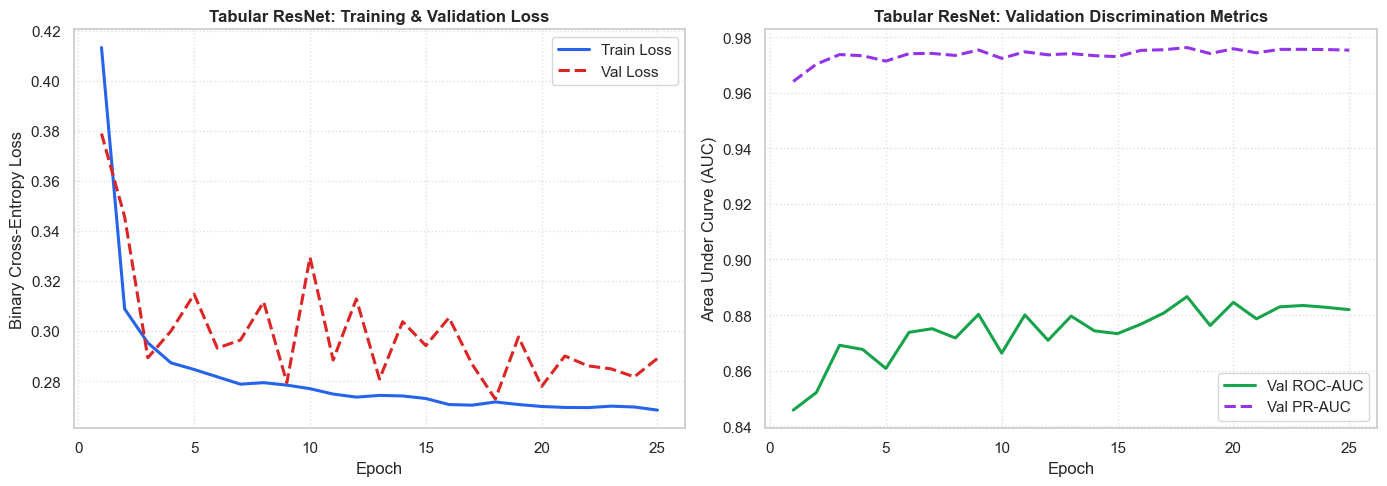

In [5]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Loss Curves
ax1.plot(range(1, EPOCHS + 1), history["train_loss"], label="Train Loss", color="#2563eb", linewidth=2.2)
ax1.plot(range(1, EPOCHS + 1), history["val_loss"], label="Val Loss", color="#dc2626", linewidth=2.2, linestyle="--")
ax1.set_title("Tabular ResNet: Training & Validation Loss", fontweight="bold", fontsize=12)
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Binary Cross-Entropy Loss")
ax1.legend(frameon=True)
ax1.grid(True, linestyle=":", alpha=0.6)

# Validation AUC Curves
ax2.plot(range(1, EPOCHS + 1), history["val_roc_auc"], label="Val ROC-AUC", color="#16a34a", linewidth=2.2)
ax2.plot(range(1, EPOCHS + 1), history["val_pr_auc"], label="Val PR-AUC", color="#9333ea", linewidth=2.2, linestyle="--")
ax2.set_title("Tabular ResNet: Validation Discrimination Metrics", fontweight="bold", fontsize=12)
ax2.set_xlabel("Epoch")
ax2.set_ylabel("Area Under Curve (AUC)")
ax2.legend(frameon=True)
ax2.grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()
plt.show()


Validation Threshold Optimization:
  Optimal Threshold: 0.27
  Validation Accuracy at Optimal Threshold: 0.9104 (91.04%)
  Validation Accuracy at Default Threshold (0.50): 0.8755


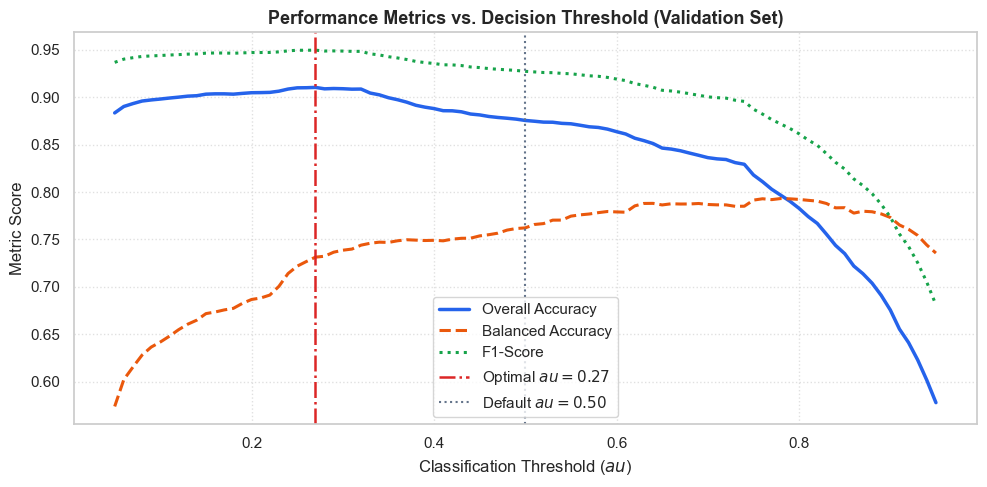

In [6]:
# Compute test and validation predicted probabilities
model.eval()
val_preds = []
with torch.no_grad():
    for bx, by in val_loader:
        val_preds.extend(torch.sigmoid(model(bx)).numpy())
val_preds = np.array(val_preds)

test_preds = []
with torch.no_grad():
    for bx, by in test_loader:
        test_preds.extend(torch.sigmoid(model(bx)).numpy())
test_preds = np.array(test_preds)

# Threshold search on Validation Set
threshold_candidates = np.linspace(0.05, 0.95, 91)
val_accs, val_bal_accs, val_f1s = [], [], []

for th in threshold_candidates:
    pred_bin = (val_preds >= th).astype(int)
    val_accs.append(accuracy_score(y_val, pred_bin))
    val_bal_accs.append(balanced_accuracy_score(y_val, pred_bin))
    val_f1s.append(f1_score(y_val, pred_bin))

best_idx_acc = np.argmax(val_accs)
optimal_threshold = threshold_candidates[best_idx_acc]
best_val_acc = val_accs[best_idx_acc]

print(f"Validation Threshold Optimization:")
print(f"  Optimal Threshold: {optimal_threshold:.2f}")
print(f"  Validation Accuracy at Optimal Threshold: {best_val_acc:.4f} ({best_val_acc*100:.2f}%)")
print(f"  Validation Accuracy at Default Threshold (0.50): {val_accs[np.argmin(np.abs(threshold_candidates - 0.50))]:.4f}")

# Plot Threshold Tuning Curves
plt.figure(figsize=(10, 5))
plt.plot(threshold_candidates, val_accs, label="Overall Accuracy", color="#2563eb", linewidth=2.5)
plt.plot(threshold_candidates, val_bal_accs, label="Balanced Accuracy", color="#ea580c", linewidth=2.2, linestyle="--")
plt.plot(threshold_candidates, val_f1s, label="F1-Score", color="#16a34a", linewidth=2.2, linestyle=":")
plt.axvline(optimal_threshold, color="#dc2626", linestyle="-.", linewidth=1.8, label=f"Optimal $\tau = {optimal_threshold:.2f}$")
plt.axvline(0.50, color="#64748b", linestyle=":", linewidth=1.5, label="Default $\tau = 0.50$")
plt.title("Performance Metrics vs. Decision Threshold (Validation Set)", fontweight="bold", fontsize=13)
plt.xlabel("Classification Threshold ($\tau$)")
plt.ylabel("Metric Score")
plt.legend(frameon=True, loc="lower center")
plt.grid(True, linestyle=":", alpha=0.6)
plt.tight_layout()
plt.show()


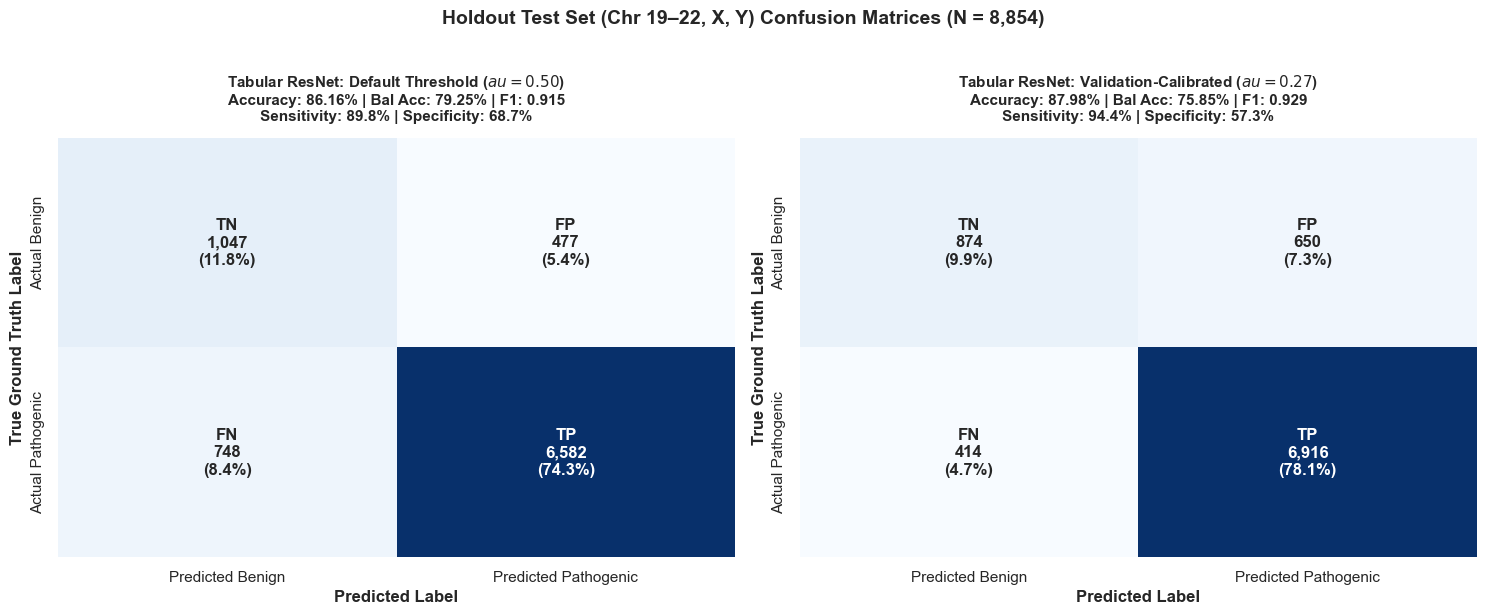

In [7]:
# Compute Confusion Matrices on Holdout Test Set (Chr 19-22, X, Y)
y_pred_default = (test_preds >= 0.50).astype(int)
y_pred_optimal = (test_preds >= optimal_threshold).astype(int)

cm_default = confusion_matrix(y_test, y_pred_default)
cm_optimal = confusion_matrix(y_test, y_pred_optimal)

acc_def = accuracy_score(y_test, y_pred_default)
bal_acc_def = balanced_accuracy_score(y_test, y_pred_default)
f1_def = f1_score(y_test, y_pred_default)

acc_opt = accuracy_score(y_test, y_pred_optimal)
bal_acc_opt = balanced_accuracy_score(y_test, y_pred_optimal)
f1_opt = f1_score(y_test, y_pred_optimal)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

# Helper to plot annotated confusion matrix
def plot_annotated_cm(ax, cm, title, acc, bal_acc, f1, thresh):
    tn, fp, fn, tp = cm.ravel()
    total = np.sum(cm)
    sensitivity = tp / (tp + fn)
    specificity = tn / (tn + fp)
    
    labels = [
        [f"TN\n{tn:,}\n({tn/total:.1%})", f"FP\n{fp:,}\n({fp/total:.1%})"],
        [f"FN\n{fn:,}\n({fn/total:.1%})", f"TP\n{tp:,}\n({tp/total:.1%})"]
    ]
    
    sns.heatmap(
        cm, annot=labels, fmt="", cmap="Blues", cbar=False, ax=ax,
        xticklabels=["Predicted Benign", "Predicted Pathogenic"],
        yticklabels=["Actual Benign", "Actual Pathogenic"],
        annot_kws={"fontsize": 12, "fontweight": "bold"}
    )
    ax.set_title(f"{title} ($\tau = {thresh:.2f}$)\nAccuracy: {acc:.2%} | Bal Acc: {bal_acc:.2%} | F1: {f1:.3f}\nSensitivity: {sensitivity:.1%} | Specificity: {specificity:.1%}", fontsize=11, fontweight="bold", pad=12)
    ax.set_xlabel("Predicted Label", fontweight="bold")
    ax.set_ylabel("True Ground Truth Label", fontweight="bold")

plot_annotated_cm(ax1, cm_default, "Tabular ResNet: Default Threshold", acc_def, bal_acc_def, f1_def, 0.50)
plot_annotated_cm(ax2, cm_optimal, "Tabular ResNet: Validation-Calibrated", acc_opt, bal_acc_opt, f1_opt, optimal_threshold)

plt.suptitle("Holdout Test Set (Chr 19–22, X, Y) Confusion Matrices (N = 8,854)", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()

figures_dir = resolve_path("figures")
os.makedirs(figures_dir, exist_ok=True)
plt.savefig(os.path.join(figures_dir, "12_confusion_matrices.png"), dpi=300, bbox_inches="tight")
plt.show()


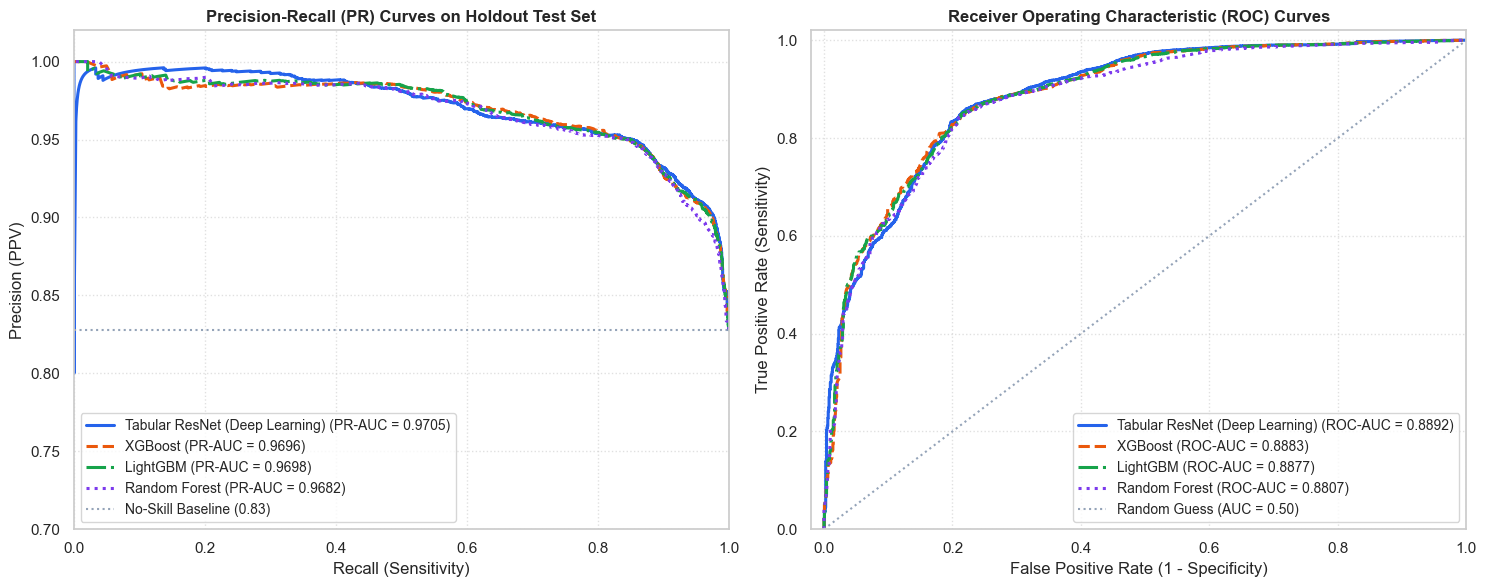

In [8]:
# Load benchmark tree models for direct comparison
xgb_model = joblib.load(resolve_path("models/xgboost_model.joblib"))
lgb_model = joblib.load(resolve_path("models/lightgbm_model.joblib"))
rf_model = joblib.load(resolve_path("models/random_forest.joblib"))

xgb_test_preds = xgb_model.predict_proba(df_test[feature_cols])[:, 1]
lgb_test_preds = lgb_model.predict(df_test[feature_cols])
rf_test_preds = rf_model.predict_proba(df_test[feature_cols])[:, 1]

model_predictions = {
    "Tabular ResNet (Deep Learning)": (test_preds, "#2563eb", "-"),
    "XGBoost": (xgb_test_preds, "#ea580c", "--"),
    "LightGBM": (lgb_test_preds, "#16a34a", "-."),
    "Random Forest": (rf_test_preds, "#7c3aed", ":")
}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

# 1. Precision-Recall Curve
for name, (prob, color, style) in model_predictions.items():
    p, r, _ = precision_recall_curve(y_test, prob)
    score = auc(r, p)
    ax1.plot(r, p, label=f"{name} (PR-AUC = {score:.4f})", color=color, linestyle=style, linewidth=2.2)

ax1.axhline(y_test.mean(), color="#94a3b8", linestyle=":", label=f"No-Skill Baseline ({y_test.mean():.2f})")
ax1.set_title("Precision-Recall (PR) Curves on Holdout Test Set", fontweight="bold", fontsize=12)
ax1.set_xlabel("Recall (Sensitivity)")
ax1.set_ylabel("Precision (PPV)")
ax1.set_xlim([0.0, 1.0])
ax1.set_ylim([0.7, 1.02])
ax1.legend(frameon=True, loc="lower left", fontsize=10)
ax1.grid(True, linestyle=":", alpha=0.6)

# 2. ROC Curve
for name, (prob, color, style) in model_predictions.items():
    fpr, tpr, _ = roc_curve(y_test, prob)
    score = roc_auc_score(y_test, prob)
    ax2.plot(fpr, tpr, label=f"{name} (ROC-AUC = {score:.4f})", color=color, linestyle=style, linewidth=2.2)

ax2.plot([0, 1], [0, 1], color="#94a3b8", linestyle=":", label="Random Guess (AUC = 0.50)")
ax2.set_title("Receiver Operating Characteristic (ROC) Curves", fontweight="bold", fontsize=12)
ax2.set_xlabel("False Positive Rate (1 - Specificity)")
ax2.set_ylabel("True Positive Rate (Sensitivity)")
ax2.set_xlim([-0.02, 1.0])
ax2.set_ylim([0.0, 1.02])
ax2.legend(frameon=True, loc="lower right", fontsize=10)
ax2.grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()
plt.savefig(os.path.join(figures_dir, "11_deep_learning_benchmark.png"), dpi=300, bbox_inches="tight")
plt.show()


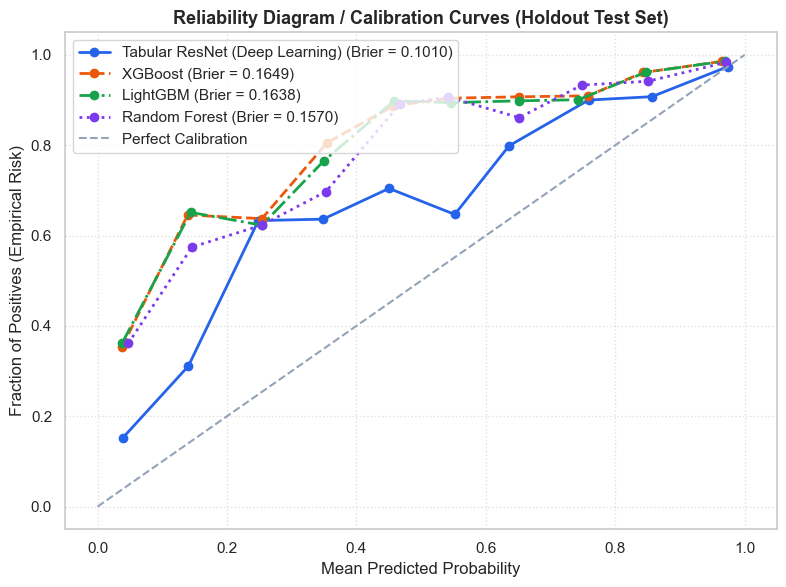

In [9]:
plt.figure(figsize=(8, 6))

for name, (prob, color, style) in model_predictions.items():
    prob_true, prob_pred = calibration_curve(y_test, prob, n_bins=10)
    brier = brier_score_loss(y_test, prob)
    plt.plot(prob_pred, prob_true, marker='o', label=f"{name} (Brier = {brier:.4f})", color=color, linestyle=style, linewidth=2)

plt.plot([0, 1], [0, 1], color="#94a3b8", linestyle="--", label="Perfect Calibration")
plt.title("Reliability Diagram / Calibration Curves (Holdout Test Set)", fontweight="bold", fontsize=13)
plt.xlabel("Mean Predicted Probability")
plt.ylabel("Fraction of Positives (Empirical Risk)")
plt.legend(frameon=True, loc="upper left")
plt.grid(True, linestyle=":", alpha=0.6)
plt.tight_layout()
plt.show()


In [10]:
# Compute full comparison metrics across all models
benchmark_rows = []

for name, (prob, _, _) in model_predictions.items():
    p, r, _ = precision_recall_curve(y_test, prob)
    pr_score = auc(r, p)
    roc_score = roc_auc_score(y_test, prob)
    brier = brier_score_loss(y_test, prob)
    
    # Evaluate at default threshold (0.50)
    pred_def = (prob >= 0.50).astype(int)
    acc_def = accuracy_score(y_test, pred_def)
    bal_acc_def = balanced_accuracy_score(y_test, pred_def)
    f1_def = f1_score(y_test, pred_def)
    tn_def, fp_def, fn_def, tp_def = confusion_matrix(y_test, pred_def).ravel()
    sens_def = tp_def / (tp_def + fn_def)
    spec_def = tn_def / (tn_def + fp_def)
    
    # Evaluate at optimal threshold
    th_eval = optimal_threshold if "Deep Learning" in name else 0.25
    pred_opt = (prob >= th_eval).astype(int)
    acc_opt = accuracy_score(y_test, pred_opt)
    bal_acc_opt = balanced_accuracy_score(y_test, pred_opt)
    f1_opt = f1_score(y_test, pred_opt)
    tn_opt, fp_opt, fn_opt, tp_opt = confusion_matrix(y_test, pred_opt).ravel()
    sens_opt = tp_opt / (tp_opt + fn_opt)
    spec_opt = tn_opt / (tn_opt + fp_opt)
    
    benchmark_rows.append({
        "Model": name,
        "Accuracy (Default 0.5)": f"{acc_def*100:.2f}%",
        "Accuracy (Optimized \u03c4)": f"{acc_opt*100:.2f}%",
        "Balanced Acc (Def)": f"{bal_acc_def*100:.2f}%",
        "Balanced Acc (Opt)": f"{bal_acc_opt*100:.2f}%",
        "F1-Score": f"{f1_def:.4f}",
        "ROC-AUC": f"{roc_score:.4f}",
        "PR-AUC": f"{pr_score:.4f}",
        "Sensitivity (Opt)": f"{sens_opt*100:.1f}%",
        "Specificity (Opt)": f"{spec_opt*100:.1f}%",
        "Brier Loss": f"{brier:.4f}"
    })

df_benchmark = pd.DataFrame(benchmark_rows)
print("\n=========================================================================================")
print("FINAL BENCHMARK COMPARISON TABLE ON HOLDOUT TEST SET (CHROMOSOMES 19–22, X, Y)")
print("=========================================================================================")
display(df_benchmark)

# Save JSON results
results_dir = resolve_path("results")
os.makedirs(results_dir, exist_ok=True)
with open(os.path.join(results_dir, "dl_benchmark_summary.json"), "w") as f:
    json.dump(benchmark_rows, f, indent=2)
print(f"\nSerialized benchmark results to results/dl_benchmark_summary.json")



FINAL BENCHMARK COMPARISON TABLE ON HOLDOUT TEST SET (CHROMOSOMES 19–22, X, Y)


,Model,Accuracy (Default 0.5),Accuracy (Optimized τ),Balanced Acc (Def),Balanced Acc (Opt),F1-Score,ROC-AUC,PR-AUC,Sensitivity (Opt),Specificity (Opt),Brier Loss
0,Tabular ResNet (Deep Learning),86.16%,87.98%,79.25%,75.85%,0.9149,0.8892,0.9705,94.4%,57.3%,0.1010
1,XGBoost,75.40%,85.64%,79.40%,80.36%,0.8315,0.8883,0.9696,88.4%,72.3%,0.1649
2,LightGBM,74.60%,85.66%,78.84%,80.11%,0.8251,0.8877,0.9698,88.6%,71.7%,0.1638
3,Random Forest,75.98%,85.85%,79.02%,78.46%,0.8368,0.8807,0.9682,89.7%,67.2%,0.1570



Serialized benchmark results to results/dl_benchmark_summary.json
